# Timestep refinement before light

**Question.** Are the social dynamics at an internal timestep of 0.03125 s sufficiently similar to 0.015625 s over the intended speed range? Can DataCollector record every 0.125 s while the social model updates every 0.03125 s?

Stage 1 found that fast fish can cross the repulsion zone between sampled updates. Here we refine time at speeds 1, 3 and 5 BL/s, using five matched random initial conditions and an equal 31.25-s physical horizon. These are 45 complete simulations: three speeds × three timesteps × five seeds. Speed 5 BL/s anticipates the upper end of the Puckett et al. (2018) model; **no light is implemented**.

The reference social model retains synchronous decide/advance, radii 0.5/3.0/5.5 BL, a 20 × 20 BL reflecting arena, 20 fish, 360° perception, zero angular noise and instantaneous social turns. Only `dt` and speed vary. These explicit controls preserve the baseline rather than silently introducing biological alternatives.

Changing `dt` also changes how often an instantaneous-turn social decision is made. This is a temporal-resolution sensitivity study of the discrete social model, not a proof of convergence to a specified continuous-time differential equation.

In [1]:
from pathlib import Path
import sys

MODEL_DIR = next(
    folder for parent in (Path.cwd(), *Path.cwd().parents)
    for folder in (parent, parent / "papers")
    if (folder / "shiner_model.py").is_file() and (folder / "handlings").is_dir()
)
if str(MODEL_DIR) not in sys.path:
    sys.path.insert(0, str(MODEL_DIR))
HERE = MODEL_DIR / "handlings" / "trial_two"

import json
import platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

from shiner_model import GoldenShinersModel
from handlings.trial_two.study_support import run_streamed

DATA = HERE / "data"
FIGURES = HERE / "figures"
DATA.mkdir(exist_ok=True)
FIGURES.mkdir(exist_ok=True)
SEEDS = list(range(5))
SPEEDS = [1.0, 3.0, 5.0]
TIMESTEPS = [0.0625, 0.03125, 0.015625]
DURATION = 31.25
RECORD_INTERVAL = 0.125
LATE_SECONDS = 12.5
print(f"Python {platform.python_version()}; explicit seeds {SEEDS}")
print(f"Internal updates per run: {[round(DURATION / dt) for dt in TIMESTEPS]}")

Python 3.11.16; explicit seeds [0, 1, 2, 3, 4]
Internal updates per run: [500, 1000, 2000]


## Predeclared practical criteria and measurements

We compare the two finest timesteps before inspecting their output. The following tolerances are **diagnostic choices for this study, not biological constants or published accuracy guarantees**:

- late polarization, MeanNND and mean distance to centroid: at most 10% change, normalized by the mean of the finest-step reference;
- late LargestGroupFraction: at most 0.05 absolute change (one fish out of 20);
- missed repulsion-zone passes: at most 0.01 per model per simulated second at the candidate timestep.

Both the difference between ensemble means and the mean absolute change of matched-seed late averages must meet the metric tolerance. The second criterion prevents changes of opposite sign from cancelling. Five seeds support a sensitivity screen; they do not establish population equivalence. We also report matched-time mean absolute errors, which reveal trajectory sensitivity but are not interpreted as a requirement that chaotic trajectories remain identical.

Late averages use the same final 12.5 simulated seconds and the same 0.125-s output grid in every condition. Connectivity and missed passes are evaluated on **every internal update**, independent of recording frequency. A missed pass means that an eligible straight relative path entered the 0.5-BL repulsion zone although both sampled endpoints were outside. Transitions involving wall reflections are excluded because their within-step paths are not straight. This measures unsampled social-zone encounters, not fish-body collisions. Exact sampled overlaps are counted separately.

Assembly means one connected geometric component continuously for at least 5 s (definition B). AssemblyTime is the beginning of the first subsequently qualifying interval; confirmation occurs 5 s later. Runs without confirmation by 31.25 s are right-censored. The attraction-radius graph is an observer-only diagnostic, distinct from the directed field of perception.

In [2]:
TOLERANCES = {
    "relative_metric_change": 0.10,
    "absolute_largest_group_fraction_change": 0.05,
    "missed_passes_per_second": 0.01,
}
metric_map = {
    "Polarization": "LatePolarization",
    "LargestGroupFraction": "LateMeanLargestGroupFraction",
    "MeanNND": "LateMeanNND",
    "MeanDistanceToCentroid": "LateMeanDistanceToCentroid",
}
rows, traces = [], []
for speed in SPEEDS:
    for dt in TIMESTEPS:
        for seed in SEEDS:
            summary, trace, _ = run_streamed(
                seed=seed, duration=DURATION, speed=speed, dt=dt,
                record_interval=RECORD_INTERVAL,
                fov_degrees=360.0, max_turn_rate=None, angular_noise=0.0,
            )
            trace = trace.copy()
            trace["Seed"], trace["Speed"], trace["dt"] = seed, speed, dt
            late = trace.loc[trace["Time"] > DURATION - LATE_SECONDS + 1e-12]
            assert len(late) == round(LATE_SECONDS / RECORD_INTERVAL)
            row = dict(summary)
            row.update(Seed=seed, Speed=speed, dt=dt, Duration_s=DURATION,
                       InternalUpdates=round(DURATION / dt),
                       RecordingInterval_s=RECORD_INTERVAL,
                       RecordEvery=round(RECORD_INTERVAL / dt))
            for original, renamed in metric_map.items():
                row[renamed] = float(late[original].mean())
            rows.append(row)
            traces.append(trace)
        print(f"Finished speed={speed:g} BL/s, dt={dt:g} s ({len(rows)}/45 runs)")
summary = pd.DataFrame(rows)
trace_all = pd.concat(traces, ignore_index=True)
summary.to_csv(DATA / "02_timestep_summary.csv", index=False)
trace_all.to_csv(DATA / "02_timestep_traces.csv", index=False)
assert len(summary) == 45
display(summary.head())
print("Summary columns:", ", ".join(summary.columns))

Finished speed=1 BL/s, dt=0.0625 s (5/45 runs)


Finished speed=1 BL/s, dt=0.03125 s (10/45 runs)


Finished speed=1 BL/s, dt=0.015625 s (15/45 runs)


Finished speed=3 BL/s, dt=0.0625 s (20/45 runs)


Finished speed=3 BL/s, dt=0.03125 s (25/45 runs)


Finished speed=3 BL/s, dt=0.015625 s (30/45 runs)


Finished speed=5 BL/s, dt=0.0625 s (35/45 runs)


Finished speed=5 BL/s, dt=0.03125 s (40/45 runs)


Finished speed=5 BL/s, dt=0.015625 s (45/45 runs)


,Seed,Duration_s,Speed,dt,RecordingInterval,InternalUpdates,SavedGroupRecords,FirstConnectionTime,ConnectedTimeFraction,MeanLargestGroupFraction,...,C_AssemblyConfirmedTime,C_Censored,C_PostAssemblyBreakup,C_BreakupCount,RecordingInterval_s,RecordEvery,LatePolarization,LateMeanLargestGroupFraction,LateMeanNND,LateMeanDistanceToCentroid
0,0,31.25,1.0,0.0625,0.125,500,251,NaN,0.000,0.5136,...,NaN,True,False,0,0.125,2,0.069303,0.500,0.604421,9.418305
1,1,31.25,1.0,0.0625,0.125,500,251,0.0,1.000,1.0000,...,5.0000,False,False,0,0.125,2,0.990259,1.000,0.563051,1.181296
2,2,31.25,1.0,0.0625,0.125,500,251,NaN,0.000,0.9048,...,12.6875,False,False,0,0.125,2,0.939016,0.950,1.126467,1.848611
3,3,31.25,1.0,0.0625,0.125,500,251,29.0,0.074,0.8283,...,NaN,True,False,0,0.125,2,0.850083,0.919,0.696982,1.941281
4,4,31.25,1.0,0.0625,0.125,500,251,NaN,0.000,0.6550,...,NaN,True,False,0,0.125,2,0.722744,0.650,0.688789,6.908873


Summary columns: Seed, Duration_s, Speed, dt, RecordingInterval, InternalUpdates, SavedGroupRecords, FirstConnectionTime, ConnectedTimeFraction, MeanLargestGroupFraction, FinalLargestGroupFraction, FinalComponentSizes, FinalGroups, LateLargestGroupFraction, LargestGroupFraction, Polarization, Rotation, MeanNND, MeanDistanceToCentroid, MissedRepulsionPasses, MissedRepulsionPassesPerSecond, EligibleStraightPairs, MinimumMissedSeparation, ExactOverlapPairs, OverlapTimeFraction, MinimumRecordedPairDistance, A_AssemblySuccess, A_AssemblyTime, A_AssemblyConfirmedTime, A_Censored, A_PostAssemblyBreakup, A_BreakupCount, B_AssemblySuccess, B_AssemblyTime, B_AssemblyConfirmedTime, B_Censored, B_PostAssemblyBreakup, B_BreakupCount, AssemblySuccess, AssemblyTime, AssemblyConfirmedTime, Censored, PostAssemblyBreakup, BreakupCount, C_AssemblySuccess, C_AssemblyTime, C_AssemblyConfirmedTime, C_Censored, C_PostAssemblyBreakup, C_BreakupCount, RecordingInterval_s, RecordEvery, LatePolarization, LateMea

In [3]:
# Use internal-update counters from the streamed observer, never decimated paths.
pass_count_column = next(name for name in ["MissedRepulsionPasses", "TotalMissedRepulsionPasses"]
                         if name in summary)
overlap_column = next(name for name in ["ExactOverlapPairs", "TotalExactOverlapPairs"]
                      if name in summary)
summary["MissedRepulsionPassesPerSecond"] = summary[pass_count_column] / DURATION
summary.to_csv(DATA / "02_timestep_summary.csv", index=False)
aggregate = summary.groupby(["Speed", "dt"]).agg(
    LatePolarization=("LatePolarization", "mean"),
    LateLargestGroupFraction=("LateMeanLargestGroupFraction", "mean"),
    LateMeanNND=("LateMeanNND", "mean"),
    LateMeanDistanceToCentroid=("LateMeanDistanceToCentroid", "mean"),
    MissedPassesPerSecond=("MissedRepulsionPassesPerSecond", "mean"),
    TotalMissedPasses=(pass_count_column, "sum"),
    ExactOverlapRecords=(overlap_column, "sum"),
    MinimumMissedSeparation_BL=("MinimumMissedSeparation", "min"),
    AssembledRuns=("AssemblySuccess", "sum"),
    MedianAssemblyTime_s=("AssemblyTime", "median"),
).reset_index()
aggregate["TravelPerUpdate_BL"] = aggregate["Speed"] * aggregate["dt"]
aggregate.to_csv(DATA / "02_timestep_aggregate.csv", index=False)
display(aggregate.round(5))

,Speed,dt,LatePolarization,LateLargestGroupFraction,LateMeanNND,LateMeanDistanceToCentroid,MissedPassesPerSecond,TotalMissedPasses,ExactOverlapRecords,MinimumMissedSeparation_BL,AssembledRuns,MedianAssemblyTime_s,TravelPerUpdate_BL
0,1.0,0.01562,0.96014,0.9769,0.58388,1.65313,0.0000,0,0,NaN,4,8.90625,0.01562
1,1.0,0.03125,0.92909,0.9700,0.72900,1.65115,0.0000,0,0,NaN,3,11.68750,0.03125
2,1.0,0.06250,0.71428,0.8038,0.73594,4.25967,0.0000,0,0,NaN,1,0.00000,0.06250
3,3.0,0.01562,0.85054,0.9000,0.53642,2.38146,0.0128,2,0,0.49844,4,6.55469,0.04688
4,3.0,0.03125,0.96046,0.9900,0.69759,1.25413,0.0128,2,0,0.49711,4,9.65625,0.09375
5,3.0,0.06250,0.74514,0.8100,0.61026,3.60751,0.0896,14,0,0.48138,3,11.50000,0.18750
6,5.0,0.01562,0.94612,0.9804,0.54910,1.39896,0.0192,3,0,0.49841,5,9.60938,0.07812
7,5.0,0.03125,0.94370,1.0000,0.58232,1.15423,0.0896,14,0,0.48200,5,7.59375,0.15625
8,5.0,0.06250,0.78633,1.0000,0.59958,1.37072,1.0368,162,0,0.42166,5,6.12500,0.31250


## Quantitative comparison of 0.03125 and 0.015625 s

`EnsembleRelativeChange` is the absolute change in the mean late statistic divided by the finest-step mean. `PairedRelativeChange` is the mean absolute matched-seed change divided by that same reference. LargestGroupFraction uses absolute units for its pass criterion, while its relative changes are also reported. Assembly success counts and times are descriptive because persistence events can be censored and event times can shift abruptly.

The 0.0625-s conditions show the direction and size of refinement over a wider range. They are not used to lower the predeclared acceptance thresholds.

In [4]:
comparison_rows = []
for speed in SPEEDS:
    coarse = summary.loc[(summary["Speed"] == speed) & (summary["dt"] == 0.03125)].set_index("Seed")
    fine = summary.loc[(summary["Speed"] == speed) & (summary["dt"] == 0.015625)].set_index("Seed")
    for source, late_name in metric_map.items():
        left, right = coarse.loc[SEEDS, late_name], fine.loc[SEEDS, late_name]
        reference = float(right.mean())
        mean_difference = float(abs(left.mean() - right.mean()))
        paired_difference = float((left - right).abs().mean())
        denominator = max(abs(reference), 1e-12)
        common = trace_all.loc[
            (trace_all["Speed"] == speed) & trace_all["dt"].isin([0.03125, 0.015625])
            & (trace_all["Time"] > DURATION - LATE_SECONDS + 1e-12)
        ].pivot(index=["Seed", "Time"], columns="dt", values=source)
        assert len(common) == len(SEEDS) * round(LATE_SECONDS / RECORD_INTERVAL)
        assert common.notna().all().all()
        absolute = source == "LargestGroupFraction"
        threshold = (TOLERANCES["absolute_largest_group_fraction_change"] if absolute
                     else TOLERANCES["relative_metric_change"])
        tested_mean = mean_difference if absolute else mean_difference / denominator
        tested_paired = paired_difference if absolute else paired_difference / denominator
        comparison_rows.append({
            "Speed": speed, "Metric": source,
            "MeanAt03125": float(left.mean()), "MeanAt015625": reference,
            "EnsembleAbsoluteChange": mean_difference,
            "EnsembleRelativeChange": mean_difference / denominator,
            "PairedAbsoluteChange": paired_difference,
            "PairedRelativeChange": paired_difference / denominator,
            "MatchedTimeMAE": float((common[0.03125] - common[0.015625]).abs().mean()),
            "Tolerance": threshold, "ToleranceUnits": "absolute" if absolute else "relative",
            "EnsemblePass": bool(tested_mean <= threshold + 1e-12),
            "PairedPass": bool(tested_paired <= threshold + 1e-12),
            "MetricPass": bool(max(tested_mean, tested_paired) <= threshold + 1e-12),
        })
comparison = pd.DataFrame(comparison_rows)
comparison.to_csv(DATA / "02_refinement_comparison.csv", index=False)
display(comparison.round(5))
pass_table = aggregate.pivot(index="Speed", columns="dt", values="MissedPassesPerSecond")
display(pass_table.round(5))

,Speed,Metric,MeanAt03125,MeanAt015625,EnsembleAbsoluteChange,EnsembleRelativeChange,PairedAbsoluteChange,PairedRelativeChange,MatchedTimeMAE,Tolerance,ToleranceUnits,EnsemblePass,PairedPass,MetricPass
0,1.0,Polarization,0.92909,0.96014,0.03104,0.03233,0.03104,0.03233,0.04679,0.10,relative,True,True,True
1,1.0,LargestGroupFraction,0.97000,0.97690,0.00690,0.00706,0.00690,0.00706,0.00690,0.05,absolute,True,True,True
2,1.0,MeanNND,0.72900,0.58388,0.14512,0.24854,0.14526,0.24878,0.14662,0.10,relative,False,False,False
3,1.0,MeanDistanceToCentroid,1.65115,1.65313,0.00197,0.00119,0.40975,0.24786,0.41556,0.10,relative,True,False,False
4,3.0,Polarization,0.96046,0.85054,0.10992,0.12924,0.15245,0.17924,0.17367,0.10,relative,False,False,False
5,3.0,LargestGroupFraction,0.99000,0.90000,0.09000,0.10000,0.11000,0.12222,0.11000,0.05,absolute,False,False,False
6,3.0,MeanNND,0.69759,0.53642,0.16117,0.30045,0.16117,0.30045,0.16234,0.10,relative,False,False,False
7,3.0,MeanDistanceToCentroid,1.25413,2.38146,1.12733,0.47338,1.60719,0.67488,1.60761,0.10,relative,False,False,False
8,5.0,Polarization,0.94370,0.94612,0.00241,0.00255,0.05040,0.05327,0.09763,0.10,relative,True,True,True
9,5.0,LargestGroupFraction,1.00000,0.98040,0.01960,0.01999,0.01960,0.01999,0.01960,0.05,absolute,True,True,True


dt,0.015625,0.031250,0.062500
Speed,,,
1.0,0.0000,0.0000,0.0000
3.0,0.0128,0.0128,0.0896
5.0,0.0192,0.0896,1.0368


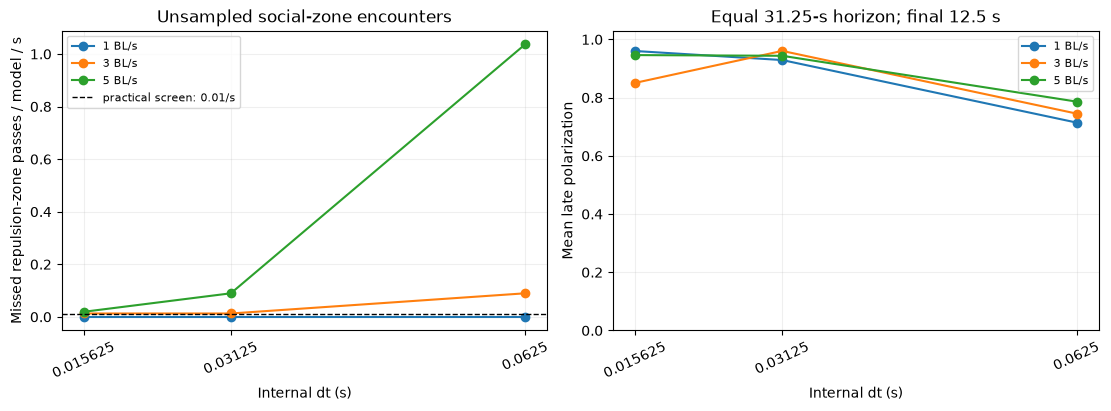

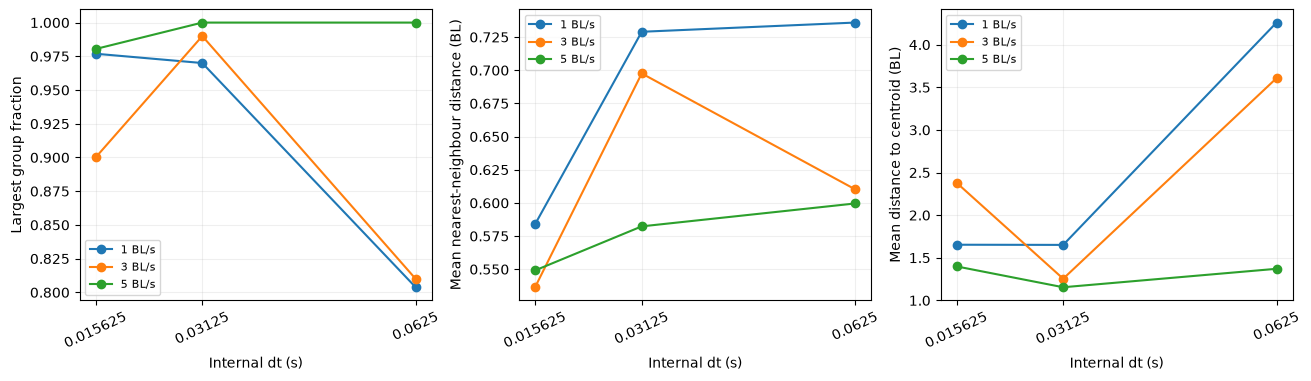

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4), constrained_layout=True)
for speed in SPEEDS:
    subset = aggregate.loc[aggregate["Speed"] == speed].sort_values("dt")
    axes[0].plot(subset["dt"], subset["MissedPassesPerSecond"], "o-", label=f"{speed:g} BL/s")
    axes[1].plot(subset["dt"], subset["LatePolarization"], "o-", label=f"{speed:g} BL/s")
axes[0].axhline(TOLERANCES["missed_passes_per_second"], color="black", ls="--", lw=1,
                label="practical screen: 0.01/s")
axes[0].set(xlabel="Internal dt (s)", ylabel="Missed repulsion-zone passes / model / s",
            title="Unsampled social-zone encounters")
axes[1].set(xlabel="Internal dt (s)", ylabel="Mean late polarization",
            title="Equal 31.25-s horizon; final 12.5 s", ylim=(0, 1.03))
for ax in axes:
    ax.set_xticks(TIMESTEPS, [str(dt) for dt in TIMESTEPS], rotation=25)
    ax.grid(alpha=0.2)
    ax.legend(fontsize=8)
fig.savefig(FIGURES / "02a_timestep_and_missed_passes.png", dpi=160)
plt.show()

fig, axes = plt.subplots(1, 3, figsize=(13, 3.7), constrained_layout=True)
for ax, metric, title in zip(axes,
    ["LateLargestGroupFraction", "LateMeanNND", "LateMeanDistanceToCentroid"],
    ["Largest group fraction", "Mean nearest-neighbour distance (BL)", "Mean distance to centroid (BL)"]):
    for speed in SPEEDS:
        subset = aggregate.loc[aggregate["Speed"] == speed].sort_values("dt")
        ax.plot(subset["dt"], subset[metric], "o-", label=f"{speed:g} BL/s")
    ax.set(xlabel="Internal dt (s)", ylabel=title)
    ax.set_xticks(TIMESTEPS, [str(dt) for dt in TIMESTEPS], rotation=25)
    ax.grid(alpha=0.2)
    ax.legend(fontsize=8)
fig.savefig(FIGURES / "02b_late_metric_sensitivity.png", dpi=160)
plt.show()

### Executed relative change in missed-pass rate

The decrease below is `(rate at 0.03125 − rate at 0.015625) / rate at 0.03125`. The rates use all internal updates over 5 × 31.25 = 156.25 model-seconds per condition.

| Speed (BL/s) | Rate at 0.03125 s | Rate at 0.015625 s | Total events, candidate → finest | Relative decrease on refinement |
|---|---:|---:|---:|---:|
| 1 | 0 | 0 | 0 → 0 | Undefined because both rates are zero |
| 3 | 0.0128 | 0.0128 | 2 → 2 | 0% |
| 5 | 0.0896 | 0.0192 | 14 → 3 | 78.6% |

At speed 5, the candidate rate is 366.7% above the finest-step rate. These rare remaining entries are shallower at the finest timestep: the minimum missed pair separation rises from 0.481998 to 0.498412 BL, close to the 0.5-BL zone boundary. They still exist and cannot be described as eliminated. Neither positive event rate should be treated as precisely estimated from only five seeds.

Polarization alone would conceal sensitivity: at speed 5 its ensemble change is only 0.25%, while mean distance to centroid changes by 17.49% in the ensemble and 30.35% in the matched-seed mean absolute comparison. At speed 1 the ensemble mean radius differs by only 0.12%, but matched-seed changes average 24.79%. This illustrates why paired and multiple-metric checks are informative.

## Separate simulation updates from DataCollector recording

This is a recording test at a **fixed** internal timestep, so the two simulations must produce exactly the same physical trajectory. We compare `record_every=1` with `record_every=4` at `dt=0.03125 s`. The second DataCollector stores one record every 0.125 s, plus the initial state. We observe and compare every internal position, heading and speed without writing them into the model or drawing random numbers.

Two matched cases are used: the deterministic reference and angular noise 0.01 rad at the model's 0.125-s reference interval. The noisy case verifies that recording does not consume random draws or change the stochastic trajectory. This is a software-invariance check, separate from the 45-run scientific comparison.

In [6]:
def fish_state(model):
    return np.asarray([[*fish.position, *fish.direction, fish.speed] for fish in model.agents], dtype=float)

stride_results = []
for noise in [0.0, 0.01]:
    fine_recording = GoldenShinersModel(seed=3, speed=5.0, dt=0.03125,
                                      record_every=1, angular_noise=noise)
    sparse_recording = GoldenShinersModel(seed=3, speed=5.0, dt=0.03125,
                                        record_every=4, angular_noise=noise)
    internal_equal = np.array_equal(fish_state(fine_recording), fish_state(sparse_recording))
    for _ in range(160):
        fine_recording.step()
        sparse_recording.step()
        internal_equal &= np.array_equal(fish_state(fine_recording), fish_state(sparse_recording))
    fine_group = fine_recording.datacollector.get_model_vars_dataframe()
    sparse_group = sparse_recording.datacollector.get_model_vars_dataframe()
    group_equal = fine_group.iloc[::4].reset_index(drop=True).equals(sparse_group.reset_index(drop=True))
    fine_fish = fine_recording.datacollector.get_agent_vars_dataframe().sort_index()
    sparse_fish = sparse_recording.datacollector.get_agent_vars_dataframe().sort_index()
    shared_fish = fine_fish.loc[fine_fish.index.get_level_values(0).isin(sparse_recording.recorded_steps)]
    agents_equal = np.array_equal(shared_fish.to_numpy(), sparse_fish.to_numpy())
    row = {"Seed": 3, "Speed": 5.0, "AngularNoise": noise,
           "SimulationDt_s": 0.03125, "RecordingInterval_s": 0.125,
           "Duration_s": 5.0, "InternalUpdates": 160,
           "FullRecordingRows": len(fine_group), "SparseRecordingRows": len(sparse_group),
           "AllInternalStatesBitwiseEqual": bool(internal_equal),
           "GroupRecordsEqualAtSharedSteps": bool(group_equal),
           "AgentRecordsEqualAtSharedSteps": bool(agents_equal),
           "RecordedInternalSteps": list(map(int, sparse_recording.recorded_steps))}
    assert internal_equal and group_equal and agents_equal
    assert len(fine_group) == 161 and len(sparse_group) == 41
    assert np.array_equal(np.diff(sparse_recording.recorded_steps), np.full(40, 4))
    stride_results.append(row)
stride_report = {"Cases": stride_results, "AllChecksPassed": True,
                 "ModelRuns": 4, "MatchedPairs": 2}
(DATA / "02_recording_stride_validation.json").write_text(json.dumps(stride_report, indent=2))
display(pd.DataFrame(stride_results).drop(columns="RecordedInternalSteps"))

,Seed,Speed,AngularNoise,SimulationDt_s,RecordingInterval_s,Duration_s,InternalUpdates,FullRecordingRows,SparseRecordingRows,AllInternalStatesBitwiseEqual,GroupRecordsEqualAtSharedSteps,AgentRecordsEqualAtSharedSteps
0,3,5.0,0.00,0.03125,0.125,5.0,160,161,41,True,True,True
1,3,5.0,0.01,0.03125,0.125,5.0,160,161,41,True,True,True


In [7]:
speed_reports = []
for speed in SPEEDS:
    metrics = comparison.loc[comparison["Speed"] == speed]
    candidate = aggregate.loc[(aggregate["Speed"] == speed) & (aggregate["dt"] == 0.03125)].iloc[0]
    finest = aggregate.loc[(aggregate["Speed"] == speed) & (aggregate["dt"] == 0.015625)].iloc[0]
    metric_pass = bool(metrics["MetricPass"].all())
    crossing_pass = bool(candidate["MissedPassesPerSecond"] <= TOLERANCES["missed_passes_per_second"] + 1e-12)
    speed_reports.append({
        "Speed": speed, "MetricCriteriaPassed": metric_pass,
        "CandidateMissedPassRate": float(candidate["MissedPassesPerSecond"]),
        "FinestMissedPassRate": float(finest["MissedPassesPerSecond"]),
        "CandidateMissedPassCriterionPassed": crossing_pass,
        "CandidateAccepted": metric_pass and crossing_pass,
        "FailedMetrics": metrics.loc[~metrics["MetricPass"], "Metric"].tolist(),
    })
readiness = {
    "ScientificRuns": 45, "RecordingValidationModelRuns": 4,
    "Seeds": SEEDS, "Speeds": SPEEDS, "Timesteps": TIMESTEPS,
    "PhysicalDuration_s": DURATION, "LateWindow_s": LATE_SECONDS,
    "RecordingInterval_s": RECORD_INTERVAL, "CandidateDt_s": 0.03125,
    "ReferenceDt_s": 0.015625, "Tolerances": TOLERANCES,
    "SpeedReports": speed_reports,
    "CandidateAcceptedAcrossAllSpeeds": all(row["CandidateAccepted"] for row in speed_reports),
    "RecordingStrideValidated": True,
    "ExactOverlapRecordsAcrossAllRuns": int(summary[overlap_column].sum()),
    "Interpretation": "A practical temporal-resolution screen, not formal ODE convergence or biological calibration.",
}
(DATA / "02_timestep_readiness.json").write_text(json.dumps(readiness, indent=2))
display(pd.DataFrame(speed_reports))
rows_text = []
for row in speed_reports:
    rows_text.append(f"- **{row['Speed']:g} BL/s:** late metric screen "
                     f"{'passes' if row['MetricCriteriaPassed'] else 'fails'}; missed passes/s "
                     f"{row['CandidateMissedPassRate']:.5f} → {row['FinestMissedPassRate']:.5f} "
                     f"on refining 0.03125 → 0.015625 s. Failed metrics: "
                     f"{', '.join(row['FailedMetrics']) or 'none'}.")
overall = ("The candidate timestep passes this finite practical screen across the tested speed range."
           if readiness["CandidateAcceptedAcrossAllSpeeds"] else
           "The candidate timestep does not pass this practical screen across the tested speed range; temporal resolution remains unresolved.")
display(Markdown("### Executed interpretation\n\n" + "\n".join(rows_text)
    + f"\n\n**{overall}**"
    + f" Across all 45 runs there were {readiness['ExactOverlapRecordsAcrossAllRuns']} exact sampled overlap records."
    + " Absence of exact overlaps does not imply absence of missed repulsion-zone entries."
    + "\n\nDataCollector decimation passed both deterministic and noisy controls: all 161 internal states "
      "were bitwise equal within each matched pair; group and fish records also matched at the 41 retained times. "
      "Thus a 0.125-s recording interval is compatible with a 0.03125-s internal update without changing these trajectories. "
      "Sparse recorded paths must not be used to estimate internal missed passes. "
      "This software result does not establish that 0.03125 s is physically adequate."))

,Speed,MetricCriteriaPassed,CandidateMissedPassRate,FinestMissedPassRate,CandidateMissedPassCriterionPassed,CandidateAccepted,FailedMetrics
0,1.0,False,0.0000,0.0000,True,False,"[MeanNND, MeanDistanceToCentroid]"
1,3.0,False,0.0128,0.0128,False,False,"[Polarization, LargestGroupFraction, MeanNND, ..."
2,5.0,False,0.0896,0.0192,False,False,[MeanDistanceToCentroid]


### Executed interpretation

- **1 BL/s:** late metric screen fails; missed passes/s 0.00000 → 0.00000 on refining 0.03125 → 0.015625 s. Failed metrics: MeanNND, MeanDistanceToCentroid.
- **3 BL/s:** late metric screen fails; missed passes/s 0.01280 → 0.01280 on refining 0.03125 → 0.015625 s. Failed metrics: Polarization, LargestGroupFraction, MeanNND, MeanDistanceToCentroid.
- **5 BL/s:** late metric screen fails; missed passes/s 0.08960 → 0.01920 on refining 0.03125 → 0.015625 s. Failed metrics: MeanDistanceToCentroid.

**The candidate timestep does not pass this practical screen across the tested speed range; temporal resolution remains unresolved.** Across all 45 runs there were 0 exact sampled overlap records. Absence of exact overlaps does not imply absence of missed repulsion-zone entries.

DataCollector decimation passed both deterministic and noisy controls: all 161 internal states were bitwise equal within each matched pair; group and fish records also matched at the 41 retained times. Thus a 0.125-s recording interval is compatible with a 0.03125-s internal update without changing these trajectories. Sparse recorded paths must not be used to estimate internal missed passes. This software result does not establish that 0.03125 s is physically adequate.

## What this tells us before light

Finer updates can reduce unsampled short-range encounters, but that improvement must be considered together with changes in polarization, connectivity and group geometry. Assembly failures within 31.25 s remain censored observations; they are not evidence of permanent inability to assemble. Equal physical time and matched initialization remove two avoidable comparison confounders.

The study has only five initial states per condition. Deterministic social decisions can amplify small timing changes and wall encounters, so paired differences can stay large even when an ensemble mean looks similar. The straight-path diagnostic excludes reflected transitions and does not resolve finite body size. Instantaneous turns are an explicit baseline assumption; imposing a finite turn rate would define a separate model sensitivity experiment and cannot be silently introduced to make this comparison pass. Sparse output reduces stored data and reporting overhead, while each internal decision still has to be computed.

**Recommendation:** use the executed table and `02_timestep_readiness.json` in the final readiness decision. Do not select 0.03125 s merely because it improves on 0.125 s, and do not infer a safe speed-5 light model from a speed-1-only result.

References: [Couzin et al. (2002)](https://doi.org/10.1006/jtbi.2002.3065) motivates local social rules; [Puckett et al. (2018)](https://doi.org/10.1038/s41598-018-26037-9) motivates the social radii and future speed range. The tolerances, persistence convention, observer geometry and recording schedule above are project implementation/diagnostic choices. No claim is made that either paper establishes these numerical acceptance thresholds.